# Iris Flower Classification

## Oasis Infobyte – Data Science Internship

### Task 1: Iris Flower Classification

### Objective

The objective of this project is to build a machine learning classification model
that can classify Iris flowers into three species:

- Iris Setosa
- Iris Versicolor
- Iris Virginica

The classification is performed using physical measurements of the flowers,
including sepal length, sepal width, petal length, and petal width.

### Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- Google Colab

In [ ]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Display plots inside the notebook
%matplotlib inline

# Set a clean plotting style
sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Loading the Dataset

The Iris dataset is a built-in dataset provided by Scikit-learn.
It contains measurements of Iris flowers belonging to three different species.

The four input features are:

- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

In [ ]:
# Load the built-in Iris dataset

iris = load_iris()

# Display the available information
print("Dataset loaded successfully.")
print("\nFeature names:")
print(iris.feature_names)

print("\nTarget names:")
print(iris.target_names)

print("\nDataset shape:")
print(iris.data.shape)

Dataset loaded successfully.

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target names:
['setosa' 'versicolor' 'virginica']

Dataset shape:
(150, 4)


## 2. Creating the DataFrame

The dataset is converted into a Pandas DataFrame so that it can be
easily inspected, analyzed, and visualized.

In [ ]:
# Create a DataFrame from the Iris features

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the target column
df["target"] = iris.target

# Add the species name
df["species"] = df["target"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 3. Understanding the Dataset

Before building machine learning models, the dataset is inspected to
understand its structure, dimensions, data types, missing values,
and statistical characteristics.

In [ ]:
# Display the first five rows

df.head()

# Display number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display data types of each column

df.dtypes

# Display general information about the dataset

df.info()

# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

# Display descriptive statistics

df.describe()



Number of rows: 150
Number of columns: 6
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## 4. Exploratory Data Analysis

### Species Distribution

The dataset contains three Iris species. We first check how many
samples belong to each species.

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


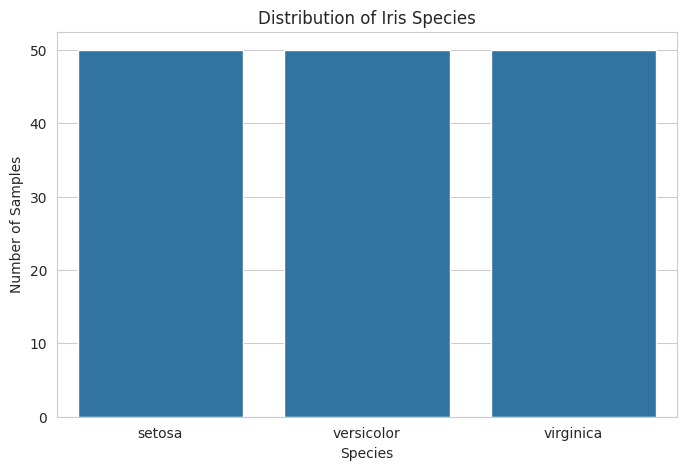

In [ ]:
# Count the number of samples in each species

print(df["species"].value_counts())

# Plot the number of samples for each species

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species"
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")

plt.show()

### Pairplot

A pairplot is used to visualize the relationships between the numerical
features and observe how well the three Iris species can be separated.

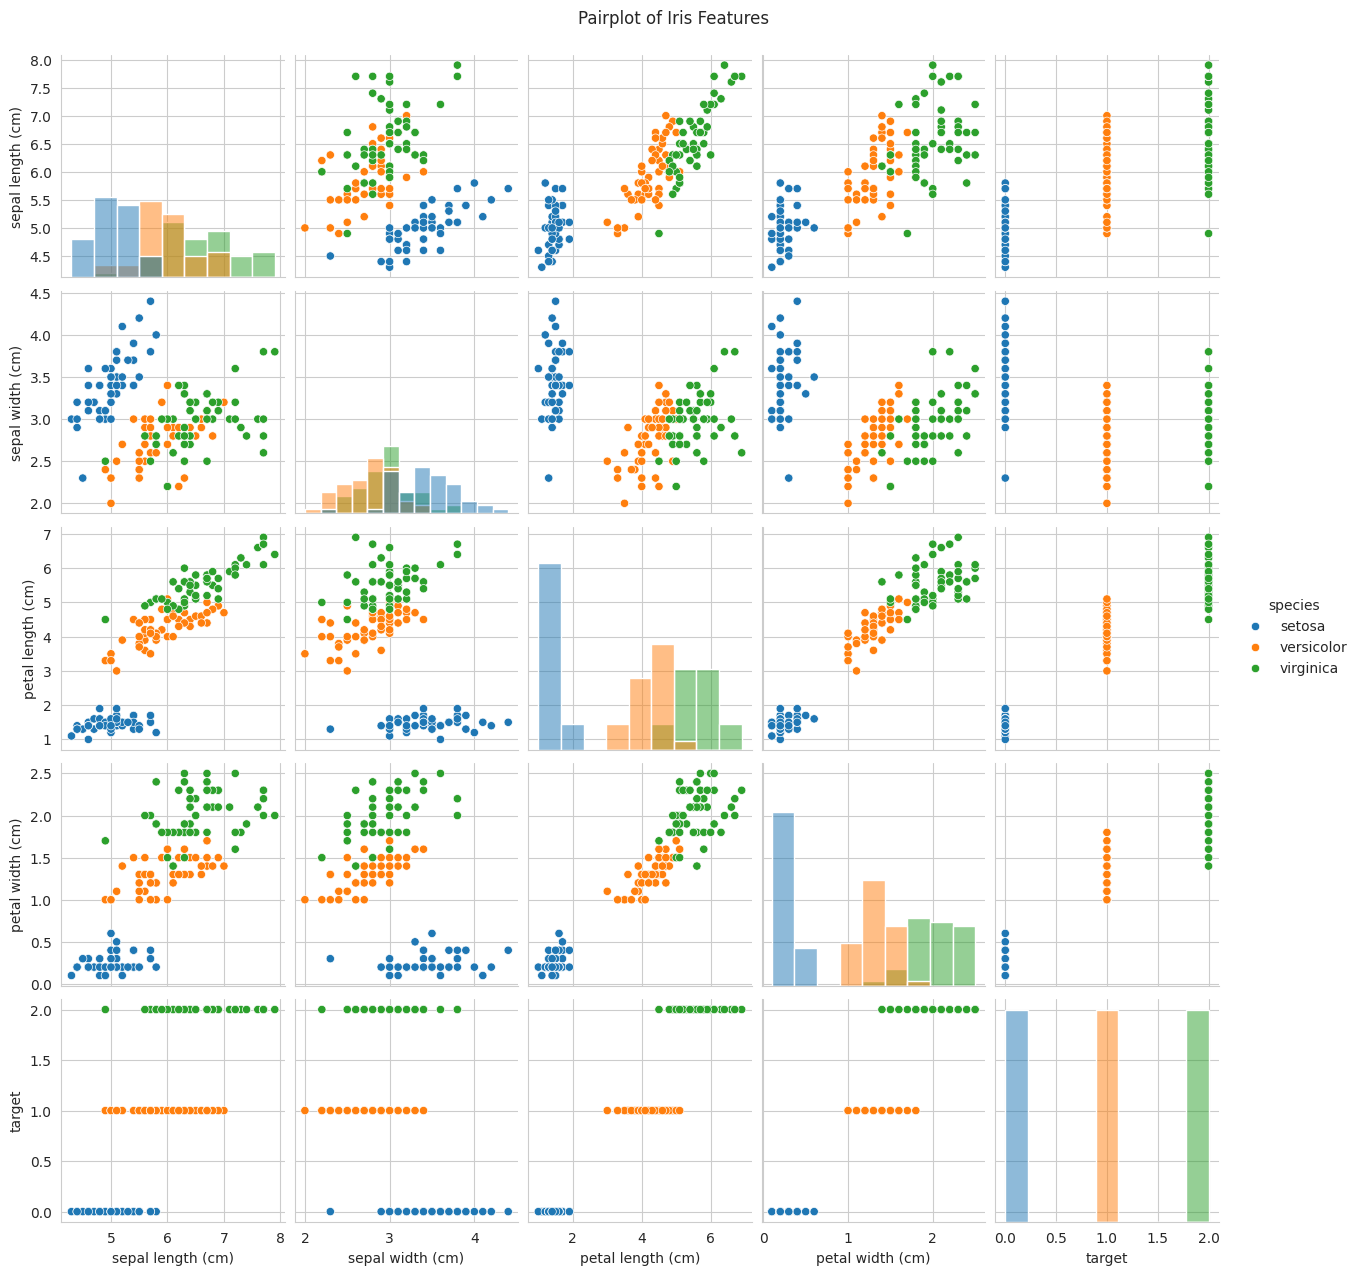

In [ ]:
# Create a pairplot for the Iris dataset

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Pairplot of Iris Features",
    y=1.02
)

plt.show()

### Boxplots

Boxplots are used to examine the distribution of each numerical feature
for the different Iris species and identify differences between groups.

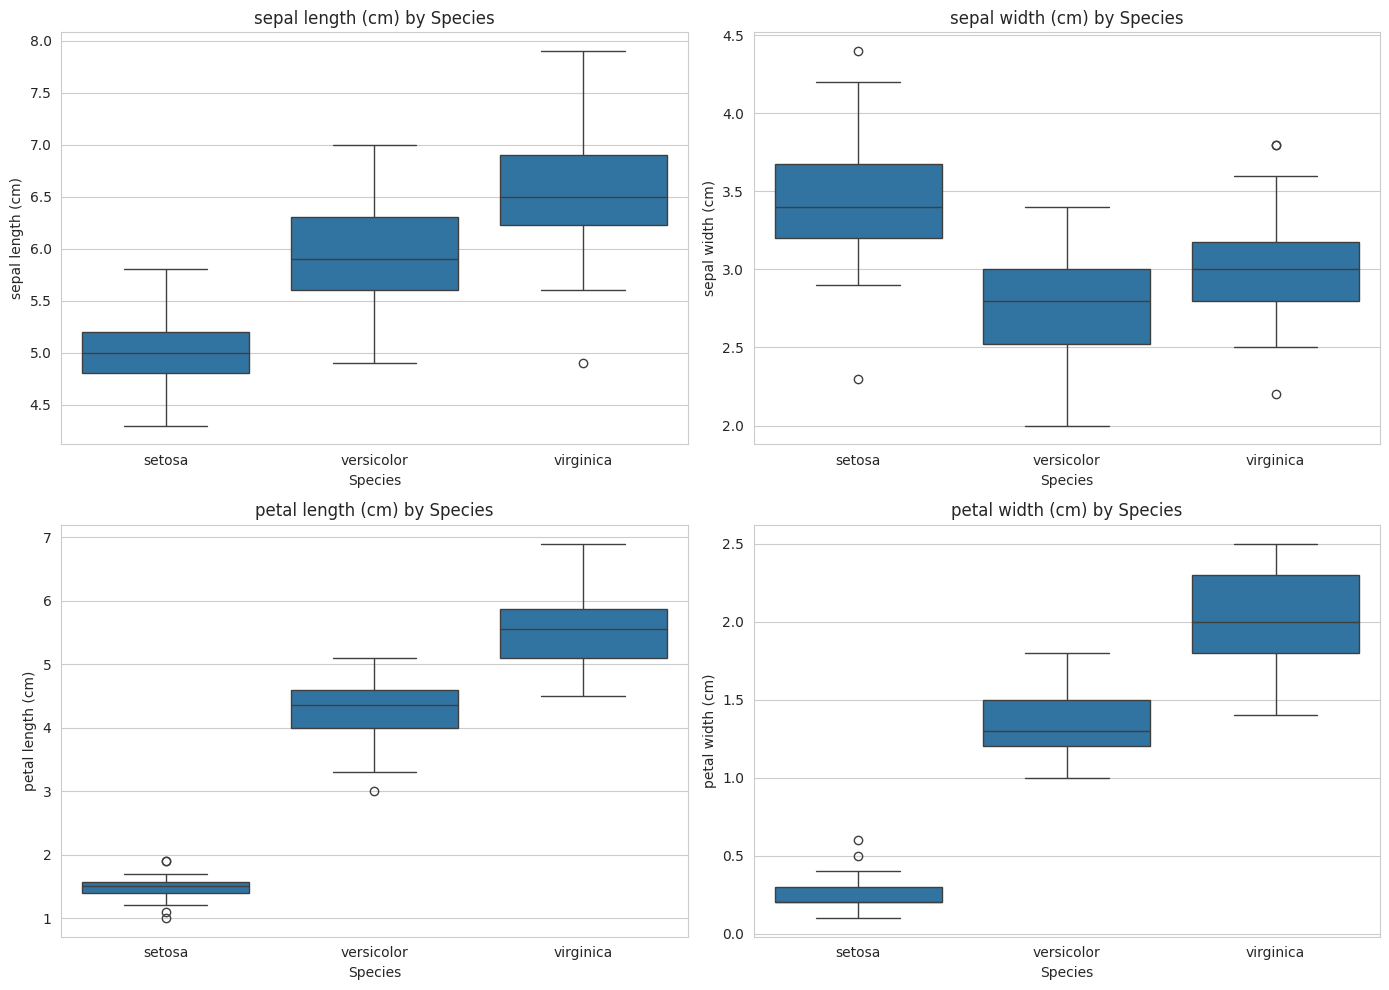

In [ ]:
# Create boxplots for all numerical features

features = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]

plt.figure(figsize=(14, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)

    sns.boxplot(
        data=df,
        x="species",
        y=feature
    )

    plt.title(f"{feature} by Species")
    plt.xlabel("Species")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

## 5. Feature Selection and Analysis

The Iris dataset contains four numerical features:

1. Sepal Length
2. Sepal Width
3. Petal Length
4. Petal Width

From the exploratory visualizations, petal length and petal width show
strong differences between the Iris species. Therefore, these features
are expected to be particularly useful for classification.

However, all four features are retained for the machine learning models
so that the classifiers can use the complete available information.

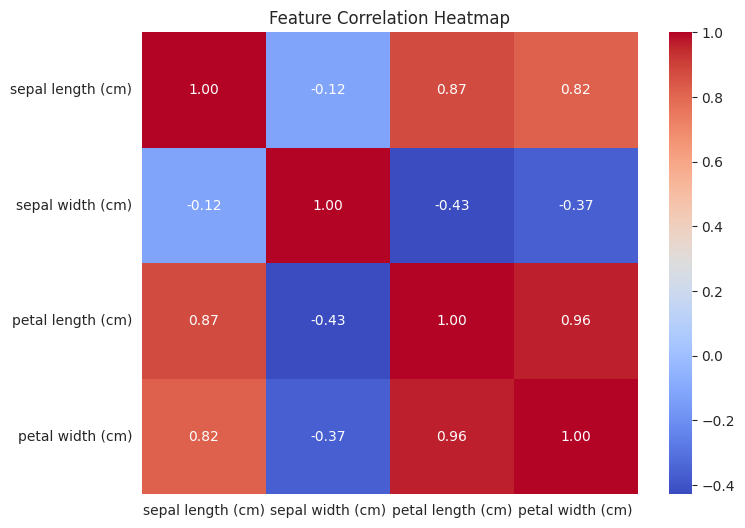

In [ ]:
# Display correlation between numerical features

plt.figure(figsize=(8, 6))

correlation_matrix = df[features].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

## 6. Preparing Data for Machine Learning

The four flower measurements are used as input features (X), while the
Iris species is used as the target variable (y).

In [ ]:
# Select input features

X = df[features]

# Select target variable
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (150, 4)
Target shape: (150,)


## 7. Train-Test Split

The dataset is divided into:

- 80% training data
- 20% testing data

The training data is used to train the models, while the testing data
is used to evaluate their performance on unseen samples.

In [ ]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


## 8. Feature Scaling

Feature scaling is applied so that the numerical features are placed on
a comparable scale. This is particularly useful for algorithms such as
Logistic Regression and K-Nearest Neighbors.

In [ ]:
# Create the scaler

scaler = StandardScaler()

# Fit the scaler only on the training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


## 9. Model 1 – Logistic Regression

Logistic Regression is a classification algorithm used to predict the
class of an observation. It is used as the first machine learning model
for Iris species classification.

In [ ]:
# Create the Logistic Regression model

logistic_model = LogisticRegression(
    max_iter=200
)

# Train the model
logistic_model.fit(
    X_train_scaled,
    y_train
)

# Make predictions
y_pred_logistic = logistic_model.predict(
    X_test_scaled
)

# Calculate accuracy
logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

print("Logistic Regression Accuracy:",
      logistic_accuracy)

Logistic Regression Accuracy: 0.9333333333333333


## 10. Model 2 – K-Nearest Neighbors

K-Nearest Neighbors (KNN) classifies a new observation based on the
classes of nearby observations in the feature space.

In [ ]:
# Create the KNN model

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# Train the model
knn_model.fit(
    X_train_scaled,
    y_train
)

# Make predictions
y_pred_knn = knn_model.predict(
    X_test_scaled
)

# Calculate accuracy
knn_accuracy = accuracy_score(
    y_test,
    y_pred_knn
)

print("KNN Accuracy:",
      knn_accuracy)

KNN Accuracy: 0.9333333333333333


## 11. Model Evaluation

The models are evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

These metrics provide a more complete evaluation than accuracy alone.

In [ ]:
# Classification report for Logistic Regression

print("Logistic Regression Classification Report")
print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=iris.target_names
    )
)

Logistic Regression Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [ ]:
# Classification report for KNN

print("KNN Classification Report")
print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=iris.target_names
    )
)

KNN Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



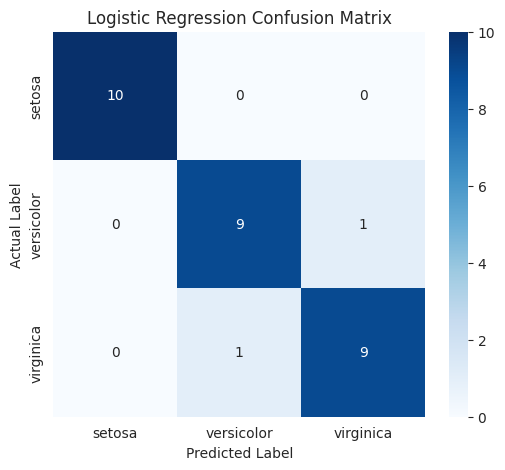

In [ ]:
# Confusion matrix for Logistic Regression

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

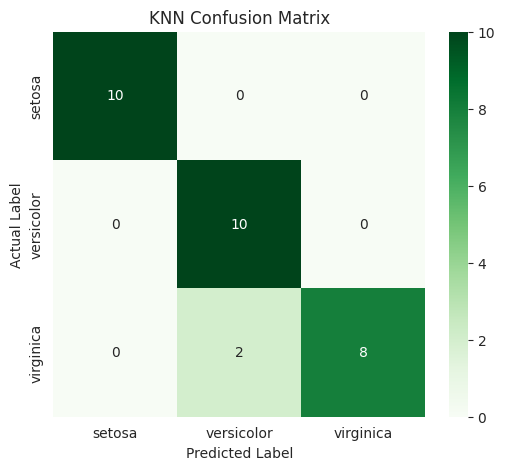

In [ ]:
# Confusion matrix for KNN

cm_knn = confusion_matrix(
    y_test,
    y_pred_knn
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

## 12. Model Comparison

The performance of both classification models is compared using their
accuracy scores.

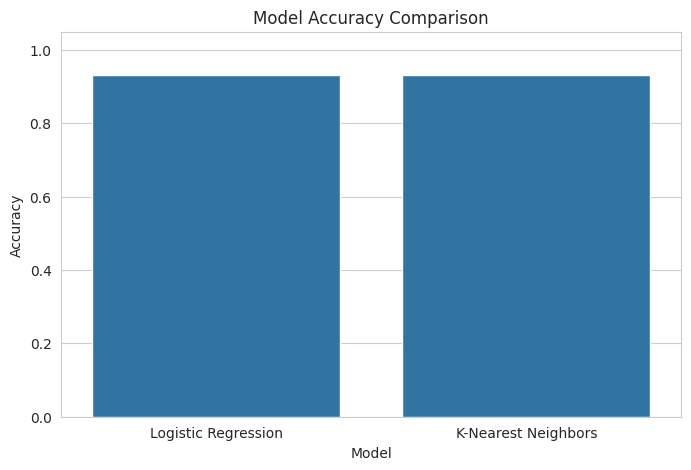

In [ ]:
# Create a DataFrame to compare the models

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbors"
    ],
    "Accuracy": [
        logistic_accuracy,
        knn_accuracy
    ]
})

# Sort models by accuracy

model_comparison = model_comparison.sort_values(
    by="Accuracy",
    ascending=False
)

model_comparison

# Plot model accuracy comparison

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1.05)

plt.show()

In [ ]:
# Identify the best-performing model

best_model = model_comparison.iloc[0]

print("Best Model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy"])

Best Model: Logistic Regression
Accuracy: 0.9333333333333333


## 13. Conclusion

In this project, machine learning techniques were used to classify Iris
flowers into Setosa, Versicolor, and Virginica species.

The Iris dataset was explored using descriptive statistics and
visualizations such as pairplots and boxplots. The analysis showed that
petal-related measurements provide strong separation between the Iris
species.

Two classification algorithms, Logistic Regression and K-Nearest
Neighbors, were trained using an 80/20 train-test split.

The models were evaluated using accuracy, precision, recall, F1-score,
and confusion matrices. The model with the highest test accuracy was
selected as the best-performing model.

Overall, the project demonstrates the complete machine learning
classification workflow, from data exploration and preprocessing to
model training, evaluation, and comparison.